# Avaliação Cruzada no Domínio Ângulo-Ordem (Order-CWT) nas 4 Arquiteturas

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT + Deep Learning  
**Datasets (Order-CWT):** CWRU, Paderborn University e XJTU-SY ($N_{\text{rev}} = 1.024$ pontos/volta, 4 voltas, $0{,}5$ a $20{,}0$ ordens)  
**Arquiteturas Avaliadas:** **BearingCNN (Rede Autoral Leve)**, **ResNet-18**, **EfficientNet-B0** e **Inception-v3**  
**Objetivo:** Avaliar sistematicamente a transferência direta de domínio (*Zero-Shot Cross-Domain*) entre os três bancos de dados nas **6 direções de transferência** utilizando escalogramas sincronizados por rotação (**Order-CWT**) nas **quatro arquiteturas**, confrontando o desempenho com o domínio Tempo-Frequência tradicional (CWT em Hz).

---

## 1. Fundamentação Física: Invariância Cinemática via *Computed Order Tracking* (COT)

Enquanto na CWT temporal tradicional as frequências características de defeito ($f_{\text{BPFI}}$, $f_{\text{BPFO}}$) escalam linearmente com a velocidade de rotação do eixo ($f_r$), no domínio ângulo-ordem cada janela é reamostrada com passo angular constante ($\Delta\theta$) ao longo de 4 revoluções completas. Dessa forma, os impactos periódicos alinham-se pelas **ordens geométricas adimensionais** do mancal.

Ao avaliar simultaneamente a rede compacta autoral (**BearingCNN**, $0{,}52\text{ M}$ parâmetros) e as três arquiteturas profundas de *Transfer Learning* (**ResNet-18**, **EfficientNet-B0** e **Inception-v3**), investigamos:
1. O ganho universal proporcionado pela **Order-CWT** na compensação da diferença de velocidade rotacional entre bancadas com resposta estrutural compatível (**CWRU $\leftrightarrow$ Paderborn**).
2. A limitação física da invariância puramente cinemática frente à divergência de função de transferência acústico-estrutural e evolução contínua de degradação (**XJTU-SY**), independentemente da profundidade do classificador neural.

## 2. Importação de Módulos e Configurações

In [1]:
import sys
from pathlib import Path

BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_xjtu', '4_cross_domain_tempo', '5_order_tracking', '6_confronto_final'] else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import torch
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from src.config import (
    ORDER_CWRU_DIR,
    ORDER_PADERBORN_DIR,
    ORDER_XJTU_DIR,
    RANDOM_SEED,
    set_seed
)
from src.cnn_processor import BearingCNN
from src.transfer_learning import build_transfer_model

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Dispositivo de inferência: {device} | Semente Fixa: {RANDOM_SEED}")

[INFO] Dispositivo de inferência: cuda | Semente Fixa: 42


## 3. Carregamento dos Conjuntos de Teste Order-CWT e Registro dos 4 Modelos

Configuramos os `DataLoaders` de teste no domínio de ordens nas resoluções $224 \times 224$ (`BearingCNN`, `ResNet-18`, `EfficientNet-B0`) e $299 \times 299$ (`Inception-v3`), mapeando os *checkpoints* treinados no notebook `02_geracao_e_treinamento_order_cwt.ipynb` e as referências da CWT temporal para cálculo da variação absoluta ($\Delta$).

In [2]:
transform_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_299 = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

ORDER_TRACKING_NB_DIR = BASE_DIR / "notebooks" / "5_order_tracking"

datasets_info = {
    "CWRU": {
        "dir": ORDER_CWRU_DIR,
        "classes": ["ball", "inner_race", "normal", "outer_race"],
        "num_classes": 4
    },
    "Paderborn": {
        "dir": ORDER_PADERBORN_DIR,
        "classes": ["inner_race", "normal", "outer_race"],
        "num_classes": 3
    },
    "XJTU-SY": {
        "dir": ORDER_XJTU_DIR,
        "classes": ["inner_race", "normal", "outer_race"],
        "num_classes": 3
    }
}

# Registro dos 4 modelos no domínio Ângulo-Ordem e referências da CWT Temporal (Notebook 4/01)
models_registry = {
    "BearingCNN": {
        "ckpts": {
            "CWRU": ORDER_TRACKING_NB_DIR / "checkpoint_order_cwru_bearing_cnn_best.pth",
            "Paderborn": ORDER_TRACKING_NB_DIR / "checkpoint_order_paderborn_bearing_cnn_best.pth",
            "XJTU-SY": ORDER_TRACKING_NB_DIR / "checkpoint_order_xjtu_bearing_cnn_best.pth",
        },
        "time_cwt_multi": {
            ("CWRU", "Paderborn"): 33.33,
            ("CWRU", "XJTU-SY"): 9.11,
            ("Paderborn", "CWRU"): 26.53,
            ("Paderborn", "XJTU-SY"): 60.44,
            ("XJTU-SY", "CWRU"): 53.06,
            ("XJTU-SY", "Paderborn"): 33.33,
        },
        "in_domain_acc": {},
        "params": "0,52 M"
    },
    "ResNet-18": {
        "ckpts": {
            "CWRU": ORDER_TRACKING_NB_DIR / "checkpoint_order_cwru_resnet18_best.pth",
            "Paderborn": ORDER_TRACKING_NB_DIR / "checkpoint_order_paderborn_resnet18_best.pth",
            "XJTU-SY": ORDER_TRACKING_NB_DIR / "checkpoint_order_xjtu_resnet18_best.pth",
        },
        "time_cwt_multi": {
            ("CWRU", "Paderborn"): 19.20,
            ("CWRU", "XJTU-SY"): 1.33,
            ("Paderborn", "CWRU"): 26.23,
            ("Paderborn", "XJTU-SY"): 66.67,
            ("XJTU-SY", "CWRU"): 20.79,
            ("XJTU-SY", "Paderborn"): 35.20,
        },
        "in_domain_acc": {},
        "params": "11,18 M"
    },
    "EfficientNet-B0": {
        "ckpts": {
            "CWRU": ORDER_TRACKING_NB_DIR / "checkpoint_order_cwru_efficientnet_b0_best.pth",
            "Paderborn": ORDER_TRACKING_NB_DIR / "checkpoint_order_paderborn_efficientnet_b0_best.pth",
            "XJTU-SY": ORDER_TRACKING_NB_DIR / "checkpoint_order_xjtu_efficientnet_b0_best.pth",
        },
        "time_cwt_multi": {
            ("CWRU", "Paderborn"): 34.13,
            ("CWRU", "XJTU-SY"): 42.67,
            ("Paderborn", "CWRU"): 29.44,
            ("Paderborn", "XJTU-SY"): 66.89,
            ("XJTU-SY", "CWRU"): 35.72,
            ("XJTU-SY", "Paderborn"): 33.07,
        },
        "in_domain_acc": {},
        "params": "4,01 M"
    },
    "Inception-v3": {
        "ckpts": {
            "CWRU": ORDER_TRACKING_NB_DIR / "checkpoint_order_cwru_inception_v3_best.pth",
            "Paderborn": ORDER_TRACKING_NB_DIR / "checkpoint_order_paderborn_inception_v3_best.pth",
            "XJTU-SY": ORDER_TRACKING_NB_DIR / "checkpoint_order_xjtu_inception_v3_best.pth",
        },
        "time_cwt_multi": {
            ("CWRU", "Paderborn"): 31.73,
            ("CWRU", "XJTU-SY"): 53.33,
            ("Paderborn", "CWRU"): 29.69,
            ("Paderborn", "XJTU-SY"): 88.89,
            ("XJTU-SY", "CWRU"): 27.67,
            ("XJTU-SY", "Paderborn"): 28.80,
        },
        "in_domain_acc": {},
        "params": "21,79 M"
    }
}

test_loaders_224 = {}
test_loaders_299 = {}
print("=" * 80)
print(" CARREGAMENTO DOS CONJUNTOS DE TESTE INÉDITOS (ORDER-CWT)")
print("=" * 80)
for name, info in datasets_info.items():
    te_ds_224 = datasets.ImageFolder(str(info["dir"] / "test"), transform=transform_224)
    te_ds_299 = datasets.ImageFolder(str(info["dir"] / "test"), transform=transform_299)
    test_loaders_224[name] = DataLoader(te_ds_224, batch_size=64, shuffle=False, num_workers=0)
    test_loaders_299[name] = DataLoader(te_ds_299, batch_size=64, shuffle=False, num_workers=0)
    print(f"[+] {name:<10} Teste Order-CWT: {len(te_ds_224):>5} amostras | Classes: {te_ds_224.classes}")


def instantiate_and_load_order(model_name: str, src: str):
    """Instancia a arquitetura solicitada e carrega os pesos Order-CWT treinados na bancada 'src'."""
    num_c = datasets_info[src]["num_classes"]
    ckpt_path = models_registry[model_name]["ckpts"][src]
    if not ckpt_path.exists():
        alt_path = Path(ckpt_path.name)
        if alt_path.exists():
            ckpt_path = alt_path
        else:
            raise FileNotFoundError(
                f"Checkpoint '{ckpt_path.name}' não encontrado! Execute o notebook 02_geracao_e_treinamento_order_cwt.ipynb antes."
            )

    if model_name == "BearingCNN":
        model = BearingCNN(num_classes=num_c)
    elif model_name == "ResNet-18":
        model, _ = build_transfer_model("resnet18", num_classes=num_c, freeze_backbone=False)
    elif model_name == "EfficientNet-B0":
        model, _ = build_transfer_model("efficientnet_b0", num_classes=num_c, freeze_backbone=False)
    elif model_name == "Inception-v3":
        model, _ = build_transfer_model("inception_v3", num_classes=num_c, freeze_backbone=False)
    else:
        raise ValueError(f"Modelo desconhecido: {model_name}")

    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model = model.to(device)
    model.eval()
    return model


def evaluate_in_domain_order(model_name: str, ds_name: str) -> float:
    """Calcula a acurácia In-Domain no conjunto de teste Order-CWT."""
    model = instantiate_and_load_order(model_name, ds_name)
    loader = test_loaders_299[ds_name] if model_name == "Inception-v3" else test_loaders_224[ds_name]
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return 100.0 * correct / total


def evaluate_order_pair(model_name: str, src: str, tgt: str):
    """Avalia o modelo Order-CWT 'model_name' treinado em 'src' diretamente sobre o teste Order-CWT de 'tgt'."""
    model = instantiate_and_load_order(model_name, src)
    loader = test_loaders_299[tgt] if model_name == "Inception-v3" else test_loaders_224[tgt]

    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            preds = model(imgs).argmax(dim=1).cpu().numpy()
            labels = labels.numpy()

            if src == "CWRU":
                # CWRU: 0: ball, 1: inner_race, 2: normal, 3: outer_race
                # Alvo (PU ou XJTU): 0: inner_race, 1: normal, 2: outer_race
                tgt_map = {0: 1, 1: 2, 2: 3}
                for l, p in zip(labels, preds):
                    all_labels.append(tgt_map[l])
                    all_preds.append(p)
            elif tgt == "CWRU":
                # Modelo PU ou XJTU avaliado no CWRU (filtra para as 3 classes comuns)
                cwru_map = {1: 0, 2: 1, 3: 2}
                for l, p in zip(labels, preds):
                    if l in cwru_map:
                        all_labels.append(cwru_map[l])
                        all_preds.append(p)
            else:
                # PU <-> XJTU (ambos com 3 classes: inner_race, normal, outer_race)
                all_labels.extend(labels)
                all_preds.extend(preds)

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    acc_multi = 100.0 * np.mean(all_labels == all_preds)

    # Detecção binária (Normal vs. Falha)
    normal_idx = 2 if src == "CWRU" else 1
    bin_labels = (all_labels != normal_idx).astype(int)
    bin_preds = (all_preds != normal_idx).astype(int)
    acc_bin = 100.0 * np.mean(bin_labels == bin_preds)

    return acc_multi, acc_bin, all_labels, all_preds


# Avaliar também as acurácias In-Domain (diagonal principal) para todos os 4 modelos
print("\n" + "=" * 80)
print(" AFERIÇÃO DAS ACURÁCIAS IN-DOMAIN (ORDER-CWT) NAS 4 ARQUITETURAS")
print("=" * 80)
for m_name in models_registry.keys():
    for ds_name in datasets_info.keys():
        models_registry[m_name]["in_domain_acc"][ds_name] = evaluate_in_domain_order(m_name, ds_name)
    accs_str = " | ".join([f"{d}: {models_registry[m_name]['in_domain_acc'][d]:.2f}%" for d in datasets_info.keys()])
    print(f"[+] {m_name:<16} -> {accs_str}")

 CARREGAMENTO DOS CONJUNTOS DE TESTE INÉDITOS (ORDER-CWT)
[+] CWRU       Teste Order-CWT:  1889 amostras | Classes: ['ball', 'inner_race', 'normal', 'outer_race']
[+] Paderborn  Teste Order-CWT:   734 amostras | Classes: ['inner_race', 'normal', 'outer_race']
[+] XJTU-SY    Teste Order-CWT:   720 amostras | Classes: ['inner_race', 'normal', 'outer_race']

 AFERIÇÃO DAS ACURÁCIAS IN-DOMAIN (ORDER-CWT) NAS 4 ARQUITETURAS
[+] BearingCNN       -> CWRU: 98.25% | Paderborn: 100.00% | XJTU-SY: 96.25%
[+] ResNet-18        -> CWRU: 100.00% | Paderborn: 100.00% | XJTU-SY: 100.00%
[+] EfficientNet-B0  -> CWRU: 98.15% | Paderborn: 100.00% | XJTU-SY: 99.31%
[+] Inception-v3     -> CWRU: 99.95% | Paderborn: 100.00% | XJTU-SY: 80.42%


## 4. Avaliação Cruzada da Arquitetura Autoral (`BearingCNN`) no Domínio Ângulo-Ordem

Avaliamos primeiramente a rede convolucional personalizada **BearingCNN** ($0{,}52\text{ M}$ parâmetros) nas 6 direções de transferência direta (*Zero-Shot*) com **Order-CWT**, gerando o painel consolidado de matrizes de confusão.

 AVALIAÇÃO ZERO-SHOT ORDER-CWT: REDE AUTORAL BEARINGCNN (0,52 M PARÂMETROS)

----------------------------------------------------------------------------------------
[BearingCNN Order-CWT] CWRU ---> Paderborn | Multi: 54.63% (Δ vs Tempo: +21.30 p.p.) | Bin: 67.30%
----------------------------------------------------------------------------------------
              precision    recall  f1-score   support

  inner_race     0.8130    0.8163    0.8147       245
      normal     0.7273    0.0327    0.0625       245
  outer_race     0.4196    0.7910    0.5483       244

   micro avg     0.5593    0.5463    0.5527       734
   macro avg     0.6533    0.5467    0.4752       734
weighted avg     0.6536    0.5463    0.4751       734


----------------------------------------------------------------------------------------
[BearingCNN Order-CWT] CWRU ---> XJTU-SY | Multi: 34.72% (Δ vs Tempo: +25.61 p.p.) | Bin: 100.00%
-----------------------------------------------------------------------------

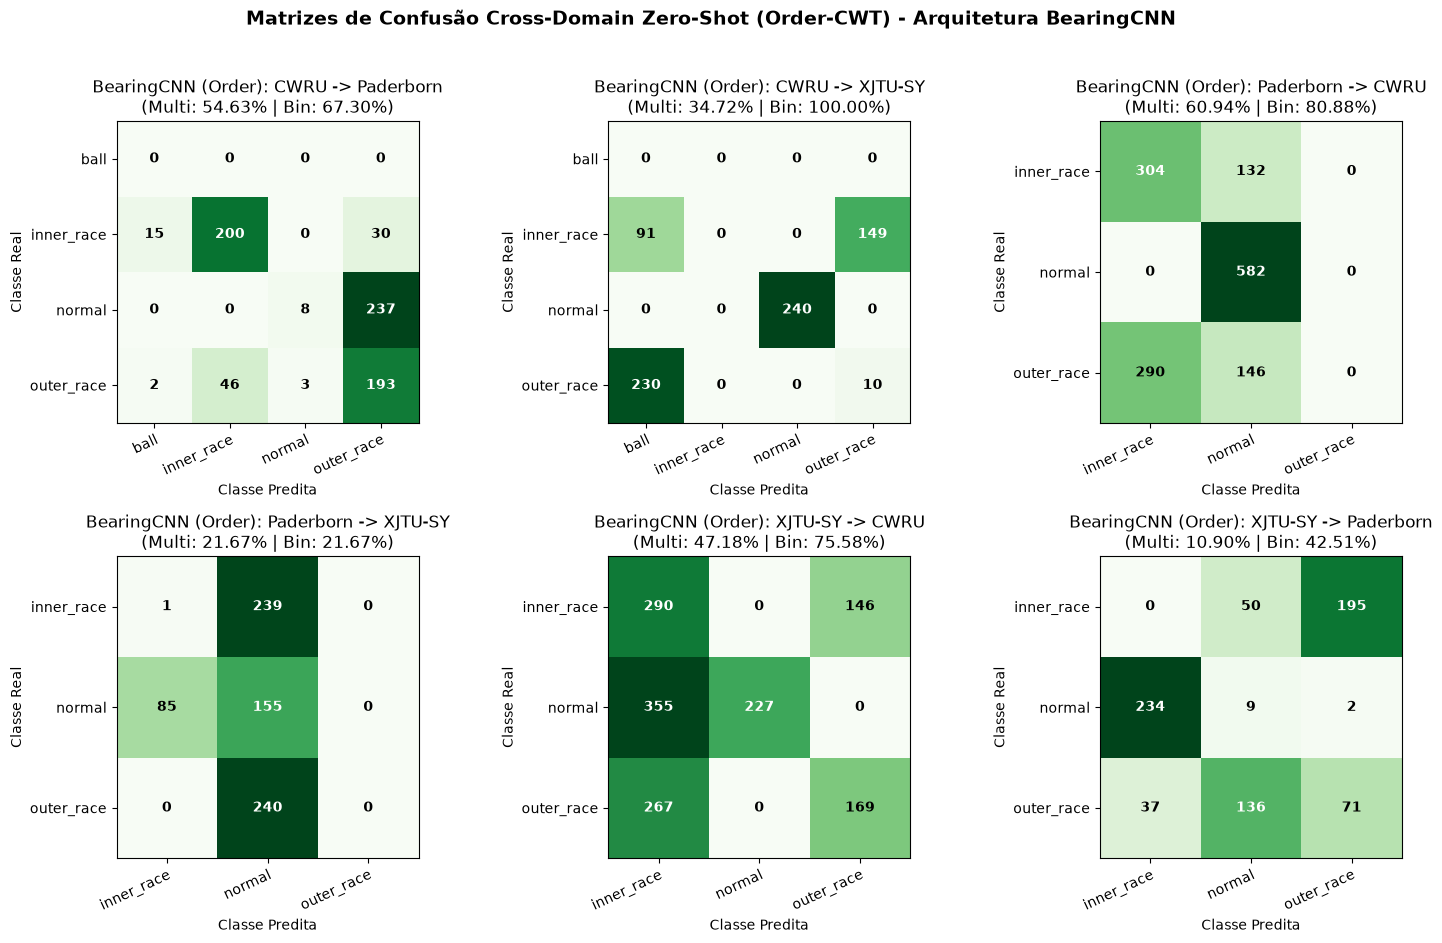

In [3]:
pairs = [
    ("CWRU", "Paderborn"),
    ("CWRU", "XJTU-SY"),
    ("Paderborn", "CWRU"),
    ("Paderborn", "XJTU-SY"),
    ("XJTU-SY", "CWRU"),
    ("XJTU-SY", "Paderborn")
]

all_models_order_results = {m: {"multi": {}, "bin": {}} for m in models_registry.keys()}

print("=" * 88)
print(" AVALIAÇÃO ZERO-SHOT ORDER-CWT: REDE AUTORAL BEARINGCNN (0,52 M PARÂMETROS)")
print("=" * 88)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.2))
axes = axes.flatten()

for idx, (src, tgt) in enumerate(pairs):
    acc_multi, acc_bin, labels, preds = evaluate_order_pair("BearingCNN", src, tgt)
    all_models_order_results["BearingCNN"]["multi"][(src, tgt)] = acc_multi
    all_models_order_results["BearingCNN"]["bin"][(src, tgt)] = acc_bin
    delta_t = acc_multi - models_registry["BearingCNN"]["time_cwt_multi"][(src, tgt)]

    print(f"\n----------------------------------------------------------------------------------------")
    print(f"[BearingCNN Order-CWT] {src} ---> {tgt} | Multi: {acc_multi:.2f}% (Δ vs Tempo: {delta_t:+.2f} p.p.) | Bin: {acc_bin:.2f}%")
    print(f"----------------------------------------------------------------------------------------")

    eval_classes = datasets_info[src]["classes"]
    target_eval_labels = [1, 2, 3] if src == "CWRU" else [0, 1, 2]
    target_eval_names = ["inner_race", "normal", "outer_race"]

    print(classification_report(
        labels, preds,
        labels=target_eval_labels,
        target_names=target_eval_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(labels, preds, labels=np.arange(len(eval_classes)))
    ax = axes[idx]
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Greens)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=eval_classes,
        yticklabels=eval_classes,
        title=f"BearingCNN (Order): {src} -> {tgt}\n(Multi: {acc_multi:.2f}% | Bin: {acc_bin:.2f}%)",
        ylabel="Classe Real",
        xlabel="Classe Predita"
    )
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0 if cm.max() > 0 else 1.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontweight="bold")

plt.suptitle("Matrizes de Confusão Cross-Domain Zero-Shot (Order-CWT) - Arquitetura BearingCNN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
bcnn_order_cm_path = BASE_DIR / "docs" / "images" / "confusion_matrix_cross_order_bearing_cnn_6pairs.png"
plt.savefig(bcnn_order_cm_path, dpi=300, bbox_inches="tight")
print(f"\n[INFO] Painel de matrizes Order-CWT da BearingCNN salvo em: {bcnn_order_cm_path.name}")
plt.show()

## 5. Avaliação Cruzada Order-CWT dos Modelos de *Transfer Learning* (`ResNet-18`, `EfficientNet-B0` e `Inception-v3`)

Na sequência, executamos o mesmo protocolo *Zero-Shot Cross-Domain* no domínio de ordens para as três arquiteturas profundas pré-treinadas no ImageNet.


 AVALIAÇÃO ZERO-SHOT ORDER-CWT: RESNET-18 (11,18 M PARÂMETROS)
[ResNet-18      ] CWRU       ---> Paderborn  | Order-CWT Multi:  43.46% (Δ vs Tempo: +24.26 p.p.) | Binária:  76.84%


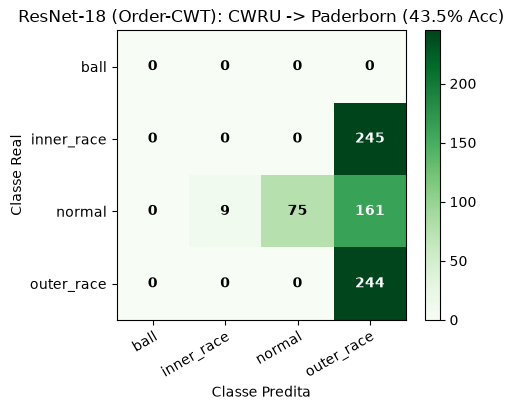

[ResNet-18      ] CWRU       ---> XJTU-SY    | Order-CWT Multi:  30.14% (Δ vs Tempo: +28.81 p.p.) | Binária:  95.97%


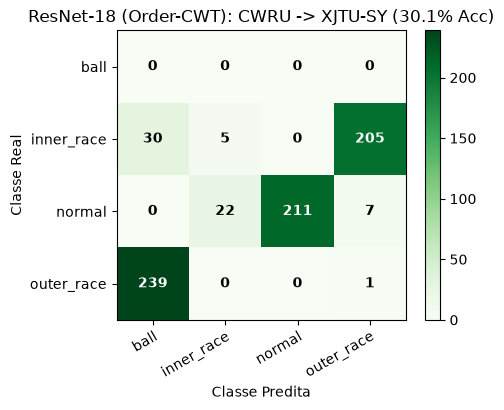

[ResNet-18      ] Paderborn  ---> CWRU       | Order-CWT Multi:  54.75% (Δ vs Tempo: +28.52 p.p.) | Binária:  64.37%


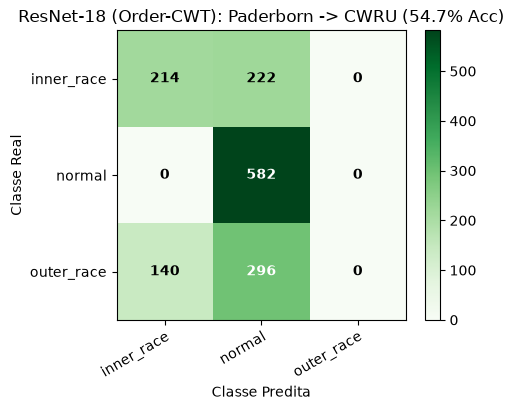

[ResNet-18      ] Paderborn  ---> XJTU-SY    | Order-CWT Multi:  33.19% (Δ vs Tempo: -33.48 p.p.) | Binária:  36.67%


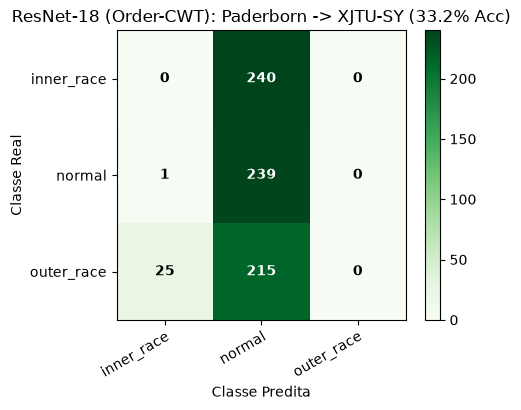

[ResNet-18      ] XJTU-SY    ---> CWRU       | Order-CWT Multi:  14.86% (Δ vs Tempo:  -5.93 p.p.) | Binária:  53.37%


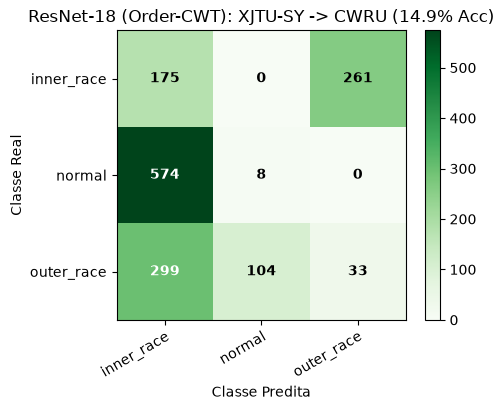

[ResNet-18      ] XJTU-SY    ---> Paderborn  | Order-CWT Multi:   3.00% (Δ vs Tempo: -32.20 p.p.) | Binária:   7.08%


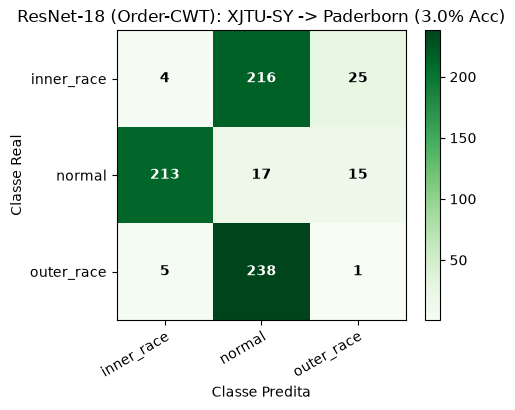


 AVALIAÇÃO ZERO-SHOT ORDER-CWT: EFFICIENTNET-B0 (4,01 M PARÂMETROS)
[EfficientNet-B0] CWRU       ---> Paderborn  | Order-CWT Multi:  33.24% (Δ vs Tempo:  -0.89 p.p.) | Binária:  66.62%
[EfficientNet-B0] CWRU       ---> XJTU-SY    | Order-CWT Multi:  24.72% (Δ vs Tempo: -17.95 p.p.) | Binária:  84.17%
[EfficientNet-B0] Paderborn  ---> CWRU       | Order-CWT Multi:  44.70% (Δ vs Tempo: +15.26 p.p.) | Binária:  48.90%
[EfficientNet-B0] Paderborn  ---> XJTU-SY    | Order-CWT Multi:  33.19% (Δ vs Tempo: -33.70 p.p.) | Binária:  33.19%
[EfficientNet-B0] XJTU-SY    ---> CWRU       | Order-CWT Multi:  36.52% (Δ vs Tempo:  +0.80 p.p.) | Binária:  69.19%
[EfficientNet-B0] XJTU-SY    ---> Paderborn  | Order-CWT Multi:  29.56% (Δ vs Tempo:  -3.51 p.p.) | Binária:  38.01%

 AVALIAÇÃO ZERO-SHOT ORDER-CWT: INCEPTION-V3 (21,79 M PARÂMETROS)
[Inception-v3   ] CWRU       ---> Paderborn  | Order-CWT Multi:  33.65% (Δ vs Tempo:  +1.92 p.p.) | Binária:  67.03%
[Inception-v3   ] CWRU       ---> XJTU-SY    

In [4]:
def plot_order_cross_cm(labels, preds, classes, title, save_path=None):
    """Gera e salva matriz de confusão individual para avaliação cruzada no domínio de ordens."""
    cm = confusion_matrix(labels, preds, labels=np.arange(len(classes)))
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Greens)
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=classes,
        yticklabels=classes,
        title=title,
        ylabel="Classe Real",
        xlabel="Classe Predita"
    )
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0 if cm.max() > 0 else 1.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontweight="bold")
    fig.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


for model_name in ["ResNet-18", "EfficientNet-B0", "Inception-v3"]:
    print("\n" + "=" * 96)
    print(f" AVALIAÇÃO ZERO-SHOT ORDER-CWT: {model_name.upper()} ({models_registry[model_name]['params']} PARÂMETROS)")
    print("=" * 96)

    for src, tgt in pairs:
        acc_multi, acc_bin, labels, preds = evaluate_order_pair(model_name, src, tgt)
        all_models_order_results[model_name]["multi"][(src, tgt)] = acc_multi
        all_models_order_results[model_name]["bin"][(src, tgt)] = acc_bin
        delta_t = acc_multi - models_registry[model_name]["time_cwt_multi"][(src, tgt)]

        print(
            f"[{model_name:<15}] {src:<10} ---> {tgt:<10} | "
            f"Order-CWT Multi: {acc_multi:6.2f}% (Δ vs Tempo: {delta_t:+6.2f} p.p.) | Binária: {acc_bin:6.2f}%"
        )

        if model_name == "ResNet-18":
            eval_classes = datasets_info[src]["classes"]
            src_slug = "xjtu" if src == "XJTU-SY" else src.lower()
            tgt_slug = "xjtu" if tgt == "XJTU-SY" else tgt.lower()
            save_name = f"confusion_matrix_cross_order_{src_slug}_to_{tgt_slug}.png"
            save_path = BASE_DIR / "docs" / "images" / save_name
            plot_order_cross_cm(
                labels, preds, eval_classes,
                title=f"ResNet-18 (Order-CWT): {src} -> {tgt} ({acc_multi:.1f}% Acc)",
                save_path=save_path
            )

## 6. Tabelas Consolidadas (Order-CWT vs. CWT Temporal) e Painel de Heatmaps $3 \times 3$ das 4 Arquiteturas

Reunimos abaixo:
1. A tabela consolidada de **Acurácia Multiclasse e Binária no Domínio Ângulo-Ordem (Order-CWT)** para todas as 4 arquiteturas.
2. A tabela comparativa direta **CWT Temporal vs. Order-CWT Angular ($\Delta$ em p.p.)** nas 4 arquiteturas, destacando tanto o par de compensação rotacional (**CWRU $\leftrightarrow$ Paderborn**) quanto a média global das 6 direções.
3. O painel $2 \times 2$ de **Heatmaps $3 \times 3$** das 4 arquiteturas no domínio de ordens.

 TABELA 1: TRANSFERÊNCIA DIRETA (ZERO-SHOT CROSS-DOMAIN) COM ORDER-CWT - TODAS AS 4 ARQUITETURAS


,Direção (Fonte -> Alvo),BearingCNN (Multi),BearingCNN (Bin),ResNet-18 (Multi),ResNet-18 (Bin),EfficientNet-B0 (Multi),EfficientNet-B0 (Bin),Inception-v3 (Multi),Inception-v3 (Bin)
0,CWRU -> Paderborn,54.63%,67.30%,43.46%,76.84%,33.24%,66.62%,33.65%,67.03%
1,CWRU -> XJTU-SY,34.72%,100.00%,30.14%,95.97%,24.72%,84.17%,1.67%,68.33%
2,Paderborn -> CWRU,60.94%,80.88%,54.75%,64.37%,44.70%,48.90%,41.13%,50.55%
3,Paderborn -> XJTU-SY,21.67%,21.67%,33.19%,36.67%,33.19%,33.19%,30.56%,30.56%
4,XJTU-SY -> CWRU,47.18%,75.58%,14.86%,53.37%,36.52%,69.19%,21.32%,59.15%
5,XJTU-SY -> Paderborn,10.90%,42.51%,3.00%,7.08%,29.56%,38.01%,14.71%,38.96%
6,MÉDIA CWRU <-> PADERBORN,57.78%,74.09%,49.10%,70.61%,38.97%,57.76%,37.39%,58.79%
7,MÉDIA CROSS-DOMAIN (6 Pares),38.34%,64.66%,29.90%,55.72%,33.66%,56.68%,23.84%,52.43%



 TABELA 2: CONFRONTO CWT TEMPORAL (Hz) vs. ORDER-CWT (ORDENS) NAS 4 ARQUITETURAS (ACURÁCIA MULTICLASSE)


,Direção (Fonte -> Alvo),BearingCNN (Tempo),BearingCNN (Ordem),BearingCNN (Δ),ResNet-18 (Tempo),ResNet-18 (Ordem),ResNet-18 (Δ),EfficientNet-B0 (Tempo),EfficientNet-B0 (Ordem),EfficientNet-B0 (Δ),Inception-v3 (Tempo),Inception-v3 (Ordem),Inception-v3 (Δ)
0,CWRU -> Paderborn,33.33%,54.63%,+21.30,19.20%,43.46%,+24.26,34.13%,33.24%,-0.89,31.73%,33.65%,+1.92
1,CWRU -> XJTU-SY,9.11%,34.72%,+25.61,1.33%,30.14%,+28.81,42.67%,24.72%,-17.95,53.33%,1.67%,-51.66
2,Paderborn -> CWRU,26.53%,60.94%,+34.41,26.23%,54.75%,+28.52,29.44%,44.70%,+15.26,29.69%,41.13%,+11.44
3,Paderborn -> XJTU-SY,60.44%,21.67%,-38.77,66.67%,33.19%,-33.48,66.89%,33.19%,-33.70,88.89%,30.56%,-58.33
4,XJTU-SY -> CWRU,53.06%,47.18%,-5.88,20.79%,14.86%,-5.93,35.72%,36.52%,+0.80,27.67%,21.32%,-6.35
5,XJTU-SY -> Paderborn,33.33%,10.90%,-22.43,35.20%,3.00%,-32.20,33.07%,29.56%,-3.51,28.80%,14.71%,-14.09
6,MÉDIA CWRU <-> PADERBORN,29.93%,57.78%,+27.85,22.71%,49.10%,+26.39,31.79%,38.97%,+7.19,30.71%,37.39%,+6.68
7,MÉDIA GLOBAL (6 Pares),35.97%,38.34%,+2.37,28.24%,29.90%,+1.66,40.32%,33.66%,-6.66,43.35%,23.84%,-19.51


[INFO] Painel 2x2 de Heatmaps Order-CWT salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\order_cross_domain_4models_heatmaps.png


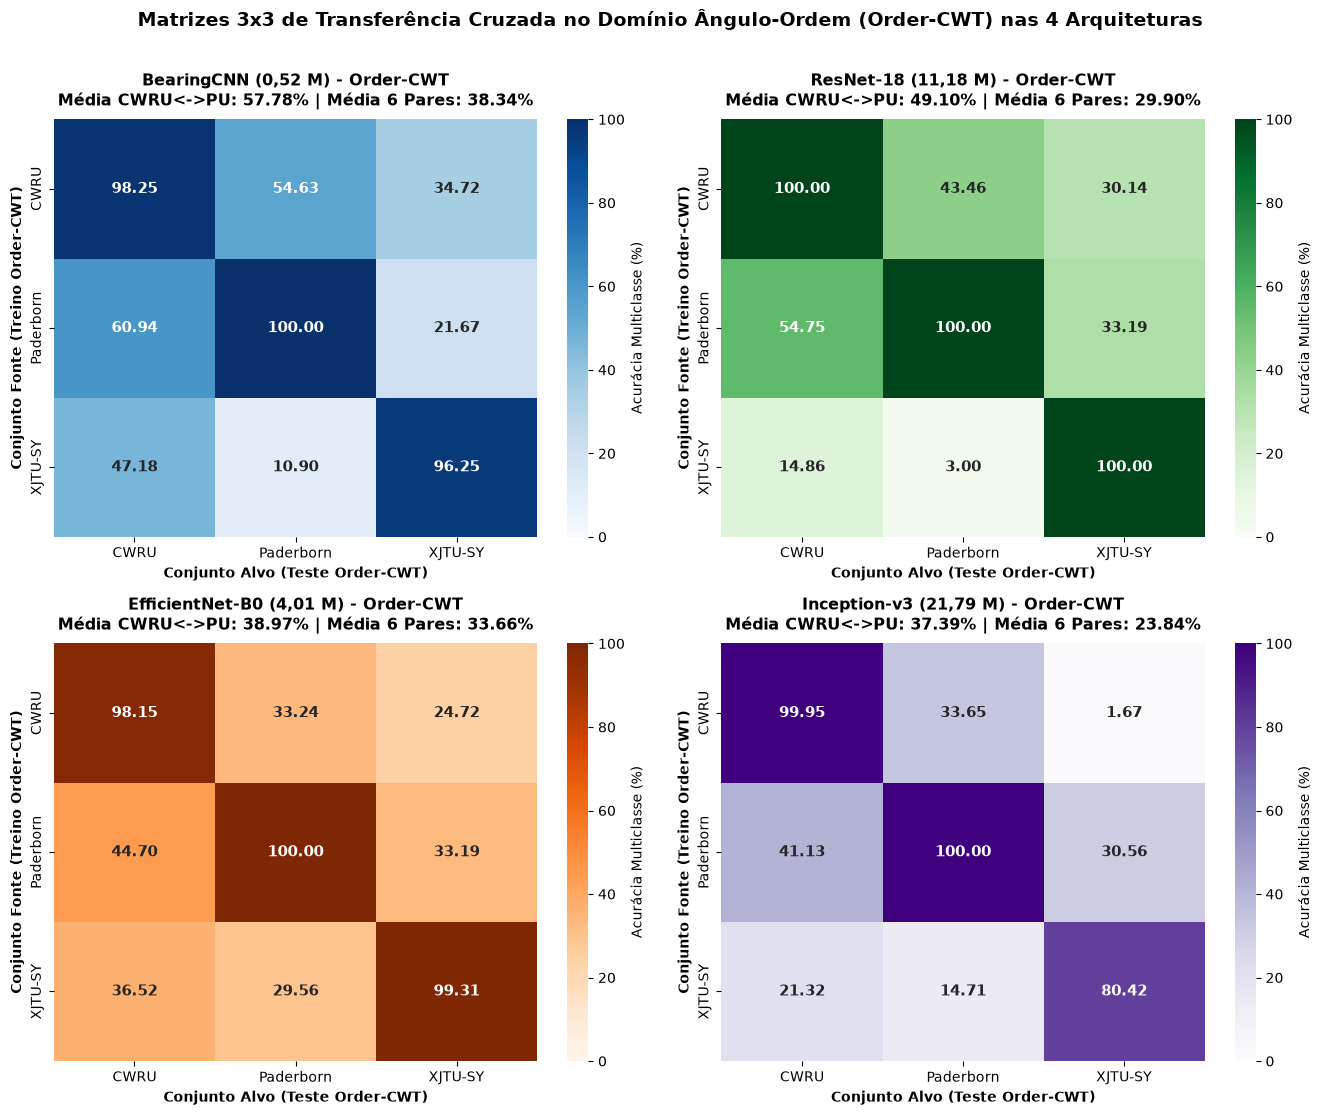

In [5]:
matrix_names = ["CWRU", "Paderborn", "XJTU-SY"]
rot_pairs = [("CWRU", "Paderborn"), ("Paderborn", "CWRU")]

# 1. Tabela Consolidada Order-CWT (Multiclasse e Binária)
summary_order_rows = []
for src, tgt in pairs:
    row = {"Direção (Fonte -> Alvo)": f"{src} -> {tgt}"}
    for m_name in models_registry.keys():
        m_acc = all_models_order_results[m_name]["multi"][(src, tgt)]
        b_acc = all_models_order_results[m_name]["bin"][(src, tgt)]
        row[f"{m_name} (Multi)"] = f"{m_acc:.2f}%"
        row[f"{m_name} (Bin)"] = f"{b_acc:.2f}%"
    summary_order_rows.append(row)

# Linha de Média CWRU <-> Paderborn (Compensação de Rotação Pura)
rot_row = {"Direção (Fonte -> Alvo)": "MÉDIA CWRU <-> PADERBORN"}
for m_name in models_registry.keys():
    m_vals = [all_models_order_results[m_name]["multi"][p] for p in rot_pairs]
    b_vals = [all_models_order_results[m_name]["bin"][p] for p in rot_pairs]
    rot_row[f"{m_name} (Multi)"] = f"{np.mean(m_vals):.2f}%"
    rot_row[f"{m_name} (Bin)"] = f"{np.mean(b_vals):.2f}%"
summary_order_rows.append(rot_row)

# Linha de Média Global Cross-Domain (6 Pares)
avg_row = {"Direção (Fonte -> Alvo)": "MÉDIA CROSS-DOMAIN (6 Pares)"}
for m_name in models_registry.keys():
    m_vals = list(all_models_order_results[m_name]["multi"].values())
    b_vals = list(all_models_order_results[m_name]["bin"].values())
    avg_row[f"{m_name} (Multi)"] = f"{np.mean(m_vals):.2f}%"
    avg_row[f"{m_name} (Bin)"] = f"{np.mean(b_vals):.2f}%"
summary_order_rows.append(avg_row)

df_order_summary = pd.DataFrame(summary_order_rows)
print("=" * 115)
print(" TABELA 1: TRANSFERÊNCIA DIRETA (ZERO-SHOT CROSS-DOMAIN) COM ORDER-CWT - TODAS AS 4 ARQUITETURAS")
print("=" * 115)
display(df_order_summary)

# 2. Tabela Comparativa CWT Temporal vs. Order-CWT (Variação Δ em p.p.)
delta_rows = []
for src, tgt in pairs:
    row = {"Direção (Fonte -> Alvo)": f"{src} -> {tgt}"}
    for m_name in models_registry.keys():
        t_acc = models_registry[m_name]["time_cwt_multi"][(src, tgt)]
        o_acc = all_models_order_results[m_name]["multi"][(src, tgt)]
        diff = o_acc - t_acc
        row[f"{m_name} (Tempo)"] = f"{t_acc:.2f}%"
        row[f"{m_name} (Ordem)"] = f"{o_acc:.2f}%"
        row[f"{m_name} (Δ)"] = f"{diff:+.2f}"
    delta_rows.append(row)

# Média CWRU <-> Paderborn
rot_delta_row = {"Direção (Fonte -> Alvo)": "MÉDIA CWRU <-> PADERBORN"}
for m_name in models_registry.keys():
    t_mean = np.mean([models_registry[m_name]["time_cwt_multi"][p] for p in rot_pairs])
    o_mean = np.mean([all_models_order_results[m_name]["multi"][p] for p in rot_pairs])
    rot_delta_row[f"{m_name} (Tempo)"] = f"{t_mean:.2f}%"
    rot_delta_row[f"{m_name} (Ordem)"] = f"{o_mean:.2f}%"
    rot_delta_row[f"{m_name} (Δ)"] = f"{o_mean - t_mean:+.2f}"
delta_rows.append(rot_delta_row)

# Média Global (6 Pares)
avg_delta_row = {"Direção (Fonte -> Alvo)": "MÉDIA GLOBAL (6 Pares)"}
for m_name in models_registry.keys():
    t_mean = np.mean(list(models_registry[m_name]["time_cwt_multi"].values()))
    o_mean = np.mean(list(all_models_order_results[m_name]["multi"].values()))
    avg_delta_row[f"{m_name} (Tempo)"] = f"{t_mean:.2f}%"
    avg_delta_row[f"{m_name} (Ordem)"] = f"{o_mean:.2f}%"
    avg_delta_row[f"{m_name} (Δ)"] = f"{o_mean - t_mean:+.2f}"
delta_rows.append(avg_delta_row)

df_delta_summary = pd.DataFrame(delta_rows)
print("\n" + "=" * 115)
print(" TABELA 2: CONFRONTO CWT TEMPORAL (Hz) vs. ORDER-CWT (ORDENS) NAS 4 ARQUITETURAS (ACURÁCIA MULTICLASSE)")
print("=" * 115)
display(df_delta_summary)

# 3. Painel 2x2 de Heatmaps 3x3 para todas as 4 arquiteturas (Order-CWT)
fig, axes = plt.subplots(2, 2, figsize=(13.5, 11))
axes = axes.flatten()
cmaps = ["Blues", "Greens", "Oranges", "Purples"]

for idx, (m_name, m_info) in enumerate(models_registry.items()):
    heat_mat = np.zeros((3, 3))
    for i, s in enumerate(matrix_names):
        for j, t in enumerate(matrix_names):
            if i == j:
                heat_mat[i, j] = m_info["in_domain_acc"][s]
            else:
                heat_mat[i, j] = all_models_order_results[m_name]["multi"][(s, t)]

    cross_mean = np.mean(list(all_models_order_results[m_name]["multi"].values()))
    rot_mean = np.mean([all_models_order_results[m_name]["multi"][p] for p in rot_pairs])
    sns.heatmap(
        heat_mat,
        annot=True,
        fmt=".2f",
        cmap=cmaps[idx],
        xticklabels=matrix_names,
        yticklabels=matrix_names,
        cbar_kws={"label": "Acurácia Multiclasse (%)"},
        vmin=0,
        vmax=100,
        annot_kws={"size": 11, "weight": "bold"},
        ax=axes[idx]
    )
    axes[idx].set_title(
        f"{m_name} ({m_info['params']}) - Order-CWT\n"
        f"Média CWRU<->PU: {rot_mean:.2f}% | Média 6 Pares: {cross_mean:.2f}%",
        fontsize=11.5, fontweight="bold", pad=10
    )
    axes[idx].set_xlabel("Conjunto Alvo (Teste Order-CWT)", fontsize=10, fontweight="bold")
    axes[idx].set_ylabel("Conjunto Fonte (Treino Order-CWT)", fontsize=10, fontweight="bold")

plt.suptitle("Matrizes 3x3 de Transferência Cruzada no Domínio Ângulo-Ordem (Order-CWT) nas 4 Arquiteturas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
heatmap_order_4models_path = BASE_DIR / "docs" / "images" / "order_cross_domain_4models_heatmaps.png"
plt.savefig(heatmap_order_4models_path, dpi=300, bbox_inches="tight")
print(f"[INFO] Painel 2x2 de Heatmaps Order-CWT salvo em: {heatmap_order_4models_path}")
plt.show()

## 7. Comparação Gráfica Global: CWT Temporal vs. Order-CWT nas 4 Arquiteturas

Geramos o painel comparativo para a monografia ilustrando:
- **Painel (a):** A evolução de acurácia em cada uma das 4 arquiteturas no par de compensação cinemática pura (**CWRU $\leftrightarrow$ Paderborn**).
- **Painel (b):** O desempenho médio global (*In-Domain*, *Cross-Domain Multiclasse* e *Detecção Binária*) das 4 arquiteturas no domínio de ordens.

[INFO] Gráfico comparativo das 4 arquiteturas salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\order_tracking_cross_domain_comparison.png


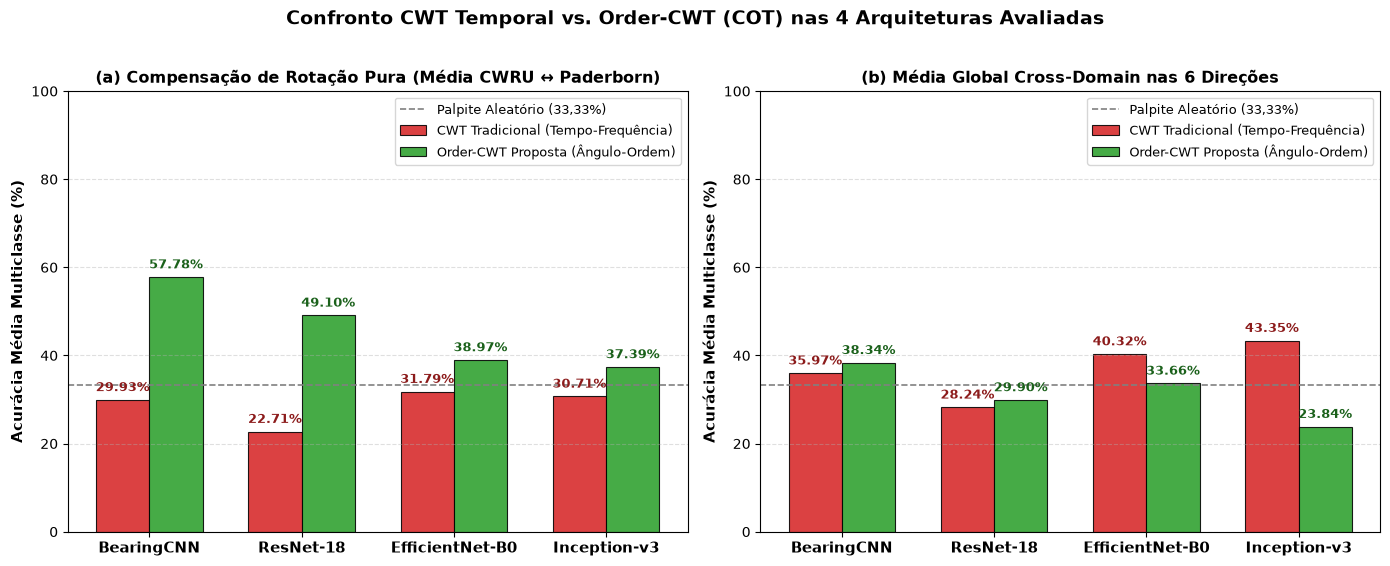

In [7]:
model_labels = list(models_registry.keys())
x = np.arange(len(model_labels))
width = 0.35

# Dados para o Painel (a): CWRU <-> Paderborn (CWT Temporal vs. Order-CWT)
rot_time_means = [np.mean([models_registry[m]["time_cwt_multi"][p] for p in rot_pairs]) for m in model_labels]
rot_order_means = [np.mean([all_models_order_results[m]["multi"][p] for p in rot_pairs]) for m in model_labels]

# Dados para o Painel (b): Média Global (6 Pares) CWT Temporal vs. Order-CWT
global_time_means = [np.mean(list(models_registry[m]["time_cwt_multi"].values())) for m in model_labels]
global_order_means = [np.mean(list(all_models_order_results[m]["multi"].values())) for m in model_labels]

fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.5))

# --- Subplot (a): Par CWRU <-> Paderborn ---
b1 = axes[0].bar(x - width/2, rot_time_means, width, label="CWT Tradicional (Tempo-Frequência)", color="#d62728", edgecolor="black", linewidth=0.8, alpha=0.88)
b2 = axes[0].bar(x + width/2, rot_order_means, width, label="Order-CWT Proposta (Ângulo-Ordem)", color="#2ca02c", edgecolor="black", linewidth=0.8, alpha=0.88)
axes[0].axhline(33.33, color="gray", linestyle="--", linewidth=1.2, label="Palpite Aleatório (33,33%)")
axes[0].set_ylabel("Acurácia Média Multiclasse (%)", fontweight="bold", fontsize=11)
axes[0].set_title("(a) Compensação de Rotação Pura (Média CWRU ↔ Paderborn)", fontweight="bold", fontsize=11.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_labels, fontweight="bold", fontsize=10.5)
axes[0].set_ylim(0, 100)
axes[0].legend(loc="upper right", fontsize=9.5)
axes[0].grid(True, linestyle="--", alpha=0.4, axis="y")

for rects, col in [(b1, "#8c1b1b"), (b2, "#1b611b")]:
    for rect in rects:
        h = rect.get_height()
        axes[0].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4),
                         textcoords="offset points", ha="center", va="bottom", fontweight="bold", fontsize=9.5, color=col)

# --- Subplot (b): Média Global das 6 Direções ---
g1 = axes[1].bar(x - width/2, global_time_means, width, label="CWT Tradicional (Tempo-Frequência)", color="#d62728", edgecolor="black", linewidth=0.8, alpha=0.88)
g2 = axes[1].bar(x + width/2, global_order_means, width, label="Order-CWT Proposta (Ângulo-Ordem)", color="#2ca02c", edgecolor="black", linewidth=0.8, alpha=0.88)
axes[1].axhline(33.33, color="gray", linestyle="--", linewidth=1.2, label="Palpite Aleatório (33,33%)")
axes[1].set_ylabel("Acurácia Média Multiclasse (%)", fontweight="bold", fontsize=11)
axes[1].set_title("(b) Média Global Cross-Domain nas 6 Direções", fontweight="bold", fontsize=11.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_labels, fontweight="bold", fontsize=10.5)
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper right", fontsize=9.5)
axes[1].grid(True, linestyle="--", alpha=0.4, axis="y")

for rects, col in [(g1, "#8c1b1b"), (g2, "#1b611b")]:
    for rect in rects:
        h = rect.get_height()
        axes[1].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4),
                         textcoords="offset points", ha="center", va="bottom", fontweight="bold", fontsize=9.5, color=col)

plt.suptitle("Confronto CWT Temporal vs. Order-CWT (COT) nas 4 Arquiteturas Avaliadas", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
comp_4models_path = BASE_DIR / "docs" / "images" / "order_tracking_cross_domain_comparison.png"
plt.savefig(comp_4models_path, dpi=300, bbox_inches="tight")
print(f"[INFO] Gráfico comparativo das 4 arquiteturas salvo em: {comp_4models_path}")
plt.show()